### RateBeer: Predicting the Overall Score a Reviewer Will Give a Beer

Summary: Using 2.86 million RateBeer reviews, ranging from 2000 to 2012, we predict the overall score, ranging from 1-20, that a user will give a beer using information that we were given prior to the review. We train on the oldest 80% of reviews and test on the newest 10%. We use bias models with added beer information, time and a user x style offset, and a latent factor model. Our best model reachest test MSE of 5.40, which is 41% lower than predicting the predicting the average. Critical information for solving this was the type of beer it is, its style and brewer, and how the user rates that style. New users are still the hardest.

Our table of contents:

*   Predictive task and evaluation plan
*   Cleaning and exploratory analysis of the Data
*   Modeling
*   Evaluation
*   Related work
*   Conclusions



### Predictive Task and Evaluation plan

Our task is to predict the overall score, 1-20, that a reviewer will give a beer by just using the information available prior to when the review is written. That includes who the reviewer is and how they rated other beers, the type of beer (its past ratings, style, brewer and ABV), and the date the review happens and the number of reviews the user has written.  

What we don't use includes the appearance, aroma, palate, and taste scores. The reviewer enters them at the same time as the overall score, so they don't exist for a beer the person hasn't tried yet. We also don't use the review text because similarly, it is written after trying the beer. We look at this review data though later to see how much of the score is shown in the review.

We evaluate using:


*   Metric: MSE on the 1 to 20 scale, and the fraction of variance unexplained.
*   Split by time: The oldest 80% of reviews for training, then the next 10 for validation, and the newest 10 for testing.
*   Baselines: We predict the training average, the beer's or user's average, and the bias only model with one offset for every user and beer.
*   Our models include the bias model with added beer information, a time and user x style offset, and a latent factor model on top all.   
*   We then compare feature representations where we add one group of information at a time and measure the change in validation MSE. In another comparison we look at text representations.  



To check that the results are valid, we:


*   Remove duplicate reviews before splitting.  
*   Ensure the models learn from training reviews only.
*   Ensure every model is scored on same test set.
*   Check there is 95% boostrap confidence intervals for the difference between models.
*   Report errors for new or rare and frequent users and beers, since heavy users dominate the overall MSE.



### Cleaning and exploratory analysis of the Data

In [ ]:
import gzip, html, os, time, string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main_color, second_color, text_color = "royalblue", "orange", "dimgray"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "gainsboro",
})

### Data Information

*   Our dataset came from the Ratebeer.txt.gz file from our professors dataset page.
*   A review contains a beer name, beer ID, brewer ID, ABV, style, a date, the reviewers profile name, the review text, and 5 scores. There is appearance (out of 5), aroma (out of 10), palate (out of 5), taste (out of 10), and the overall (out of 20). The 5 add up to 50 points and then divided by 10 to get a final rating out of 5.
*   This data was collected for for research on reviews that rate several aspects of a product (McAuley, Leskovec & Jurafsky, "Learning attitudes and attributes from multi-aspect reviews", ICDM 2012) and on how reviewers' tastes change as they gain experience (McAuley & Leskovec, "From amateurs to connoisseurs", WWW 2013).
*   The dataset page says this has 2,855,232 reviews, 40,213 users and 110,419 beers, April 2000 to November 2011. Our own counts are shown later.




In [ ]:
import os
if "google.colab" in str(get_ipython()):
    from google.colab import drive
    drive.mount("/content/drive")
    !cp "/content/drive/MyDrive/Ratebeer.txt.gz" /content/Ratebeer.txt.gz
print("found data", os.path.exists("Ratebeer.txt.gz"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
found data True


In [ ]:
DATA_PATH = "Ratebeer.txt.gz"

field_names = {
    "beer/name": "beer_name", "beer/beerId": "beer_id", "beer/brewerId": "brewer_id",
    "beer/ABV": "abv", "beer/style": "beer_style", "review/appearance": "appearance",
    "review/aroma": "aroma", "review/palate": "palate", "review/taste": "taste",
    "review/overall": "overall", "review/time": "time", "review/profileName": "user",
    "review/text": "text",
}
column_values = {name: [] for name in field_names.values()}
shared_copy = {}
record, incomplete_records = {}, 0

def save_record(record):
    global incomplete_records
    if len(record) != len(field_names):
        incomplete_records += 1
        return
    for column_name, value in record.items():
        if column_name != "text":
            value = shared_copy.setdefault(value, value)
        column_values[column_name].append(value)

# Is plain text with one "key: value" line per field and also Latin1 encoded
with gzip.open(DATA_PATH, "rt", encoding="latin-1") as file:
    for line in file:
        line = line.rstrip("\n")
        if line == "":
            if record:
                save_record(record)
                record = {}
            continue
        key, _, value = line.partition(": ")
        if key in field_names:
            record[field_names[key]] = value.strip()
    if record:
        save_record(record)

df = pd.DataFrame(column_values)
del column_values, shared_copy

print(f"Reviews loaded: {len(df):,} | incomplete records skipped: {incomplete_records} ")
display(df.head(3))

Reviews loaded: 2,924,163 | incomplete records skipped: 0 


,beer_name,beer_id,brewer_id,abv,beer_style,appearance,aroma,palate,taste,overall,time,user,text
0,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,3/5,6/10,13/20,1157587200,hopdog,"On tap at the Springfield, PA location. Poured..."
1,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,4/5,7/10,13/20,1157241600,TomDecapolis,On tap at the John Harvards in Springfield PA....
2,John Harvards Cristal Pilsner,71716,8481,5,Bohemian Pilsener,4/5,5/10,3/5,6/10,14/20,958694400,PhillyBeer2112,"UPDATED: FEB 19, 2003 Springfield, PA. I've ne..."


Every review was read fully and every field including numbers are strings which need to be converted.

### Cleaning Data

Missing values!

isnull() only sees the None and NaN so some other empty values such as '-' or an empty string '' was not found.  
To fix this, we:
*   count what isnull() reports first.
*   scan every column for values that are empty, made only of symbols, or common empty words such as n/a or null,and convert the real placeholders to NaN

In [ ]:
print("Missing values from isnull() is ", df.isnull().sum().sum())
null_words = ["n/a", "na", "null", "none", "nan", "unknown", "missing"]
scan_rows = []
for column_name in df.columns:
    values = df[column_name].str.strip()
    scan_rows.append({"column": column_name,
                      "empty": (values == "").sum(),
                      "symbols only": (~values.str.contains(r"[A-Za-z0-9]") & (values != "")).sum(),
                      "missing words": values.str.lower().isin(null_words).sum()})
scan = pd.DataFrame(scan_rows).set_index("column")
display(scan[scan.sum(axis=1) > 0])
system_messages = [
    "(This beer rating was imported from FB and unfortunately lacks any further comments.)",
    "Imported from Beerseek, no description given with original rating. Need to re-rate beer.",
]
no_letters = ~df["text"].str.contains(r"[A-Za-z]")
import_message = df["text"].str.strip().isin(system_messages)
print("Texts with no letters is ", no_letters.sum(), " and the import messages is ", import_message.sum(),
      " and the reviews by a user named 'missing' is ", (df["user"] == "missing").sum())
df["abv"] = df["abv"].replace("-", np.nan)
df.loc[no_letters | import_message, "text"] = np.nan
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "% of reviews": (missing / len(df) * 100).round(2)})[missing > 0]

Missing values from isnull() is  0


,empty,symbols only,missing words
column,,,
abv,0,138637,0
user,0,0,68
text,5002,86,0


Texts with no letters is  5110  and the import messages is  75  and the reviews by a user named 'missing' is  68


,missing,% of reviews
abv,138637,4.74
text,5185,0.18


Before cleaning, isnull() shows 0 missing values, but the scan finds hidden ones. The abv column has reviews with '-'. The text column has reviews that are empty or contain only symbols, and some are automatic messages saying the review has no comments. The user column has a profile literally named 'missing', but its reviews look like a real user's, so we keep it. After cleaning, pandas sees 138,637 missing ABVs and 5,185 missing texts.

## Now we convert the text to numbers and dates

In [ ]:
for column_name in ["appearance", "aroma", "palate", "taste", "overall"]:
    values = df[column_name].unique()
    score_of = {value: int(value.split("/")[0]) for value in values}
    maximums = {int(value.split("/")[1]) for value in values}
    df[column_name] = df[column_name].map(score_of)
    print(column_name, "maximum:", maximums, "| range:", df[column_name].min(), "to", df[column_name].max())

df["abv"] = pd.to_numeric(df["abv"])
df["time"] = pd.to_numeric(df["time"])
df["date"] = pd.to_datetime(df["time"], unit="s")
print("Dates:", df["date"].min().date(), "to", df["date"].max().date(),
      "| timestamps not at midnight:", (df["time"] % 86400 != 0).sum())
print("ABV range:", df["abv"].min(), "to", df["abv"].max())

appearance maximum: {5} | range: 1 to 5
aroma maximum: {10} | range: 1 to 10
palate maximum: {5} | range: 1 to 5
taste maximum: {10} | range: 1 to 10
overall maximum: {20} | range: 1 to 20
Dates: 2000-04-12 to 2012-01-13 | timestamps not at midnight: 0
ABV range: 0.01 to 57.7


- Every score has the form score/maximum, and no score falls outside its range.
- Every timestamp is exactly midnight, so we know the date of a review but not the time of day.
- ABV runs from 0.01% to 57.7%. These are real beers (alcohol free beers and an extreme eisbock), so nothing is removed.

## HTML codes in names, styles and text

Names and styles contain web codes such as `&#40;` for "(". We decode them with `html.unescape`. Accented letters such as "Kölsch" fine.

In [ ]:
html_code_pattern = r"&#?[A-Za-z0-9]+;"
print("Reviews with HTML codes include", df["beer_name"].str.contains(html_code_pattern).sum(),
      "names,", df["beer_style"].str.contains(html_code_pattern).sum(),
      "styles and", df["text"].str.contains(html_code_pattern, na=False).sum(), "texts")

for column_name in ["beer_name", "beer_style"]:
    cleaned_value_of = {value: html.unescape(value) for value in df[column_name].unique()}
    df[column_name] = df[column_name].map(cleaned_value_of)
text_has_code = df["text"].str.contains(html_code_pattern, na=False)
df.loc[text_has_code, "text"] = df.loc[text_has_code, "text"].apply(html.unescape)

print("Example", df.loc[0, "beer_style"])

Reviews with HTML codes include 214417 names, 234046 styles and 4547 texts
Example India Pale Ale (IPA)


## Duplicates


In [ ]:
pair_columns = ["user", "beer_id"]
print("Number of exact duplicate rows is ", df.duplicated().sum(),
      "and the extra copies of a (user, beer) pair is", df.duplicated(subset=pair_columns).sum())

# Figure out what differs
repeated = df[df.duplicated(subset=pair_columns, keep=False)].groupby(pair_columns)
for column_name in ["brewer_id", "overall", "text", "date"]:
    print("pairs whose copies differ in", column_name, ":", (repeated[column_name].nunique(dropna=False) > 1).sum())

df = df.drop_duplicates(subset=pair_columns).reset_index(drop=True)
print("Reviews after removing copies:", len(df))

Number of exact duplicate rows is  4 and the extra copies of a (user, beer) pair is 68931
pairs whose copies differ in brewer_id : 68926
pairs whose copies differ in overall : 1
pairs whose copies differ in text : 2
pairs whose copies differ in date : 0
Reviews after removing copies: 2855232


Only 4 rows are exact copies, but 68,931 reviews appear twice, identical except for the brewer ID. These beers are listed under two brewers, so each review was collected once from each brewer's page. We keep the first copy, so no review can appear in both training and test.

This leaves 2,855,232 reviews, exactly the number on the dataset page, which confirms the duplicates were collection artifacts.

## Basic statistics

In [ ]:
reviews_per_user = df["user"].value_counts()
reviews_per_beer = df["beer_id"].value_counts()
df["word_count"] = df["text"].str.count(r"\S+")
density = len(df) / (df["user"].nunique() * df["beer_id"].nunique()) * 100

pd.DataFrame({"value": [
    f"{len(df):,}", f"{df['user'].nunique():,}", f"{df['beer_id'].nunique():,}", f"{df['brewer_id'].nunique():,}",
    f"{df['beer_style'].nunique()}", f"{df['date'].min().date()} to {df['date'].max().date()}",
    f"{df['word_count'].median():.0f}", f"{density:.3f}%",
]}, index=["reviews", "users (profile names)", "beers", "brewers", "styles", "dates",
           "median words per review", "density: reviews / (users x beers)"])

,value
reviews,"2,855,232"
users (profile names),"29,265"
beers,"110,369"
brewers,"7,424"
styles,89
dates,2000-04-12 to 2012-01-13
median words per review,44
density: reviews / (users x beers),0.088%


*   We have fewer users than the dataset page (29,265 vs. 40,213) because the file only has profile names and not user IDs.
*   Only 0.088% of all possible (user, beer) pairs have a review, so user-beer rating matrix is extremely sparse.

Our target is the overall score.

mean 13.24 | variance 11.07 | skew -1.03
share of scores from 12 to 17: 71.0%


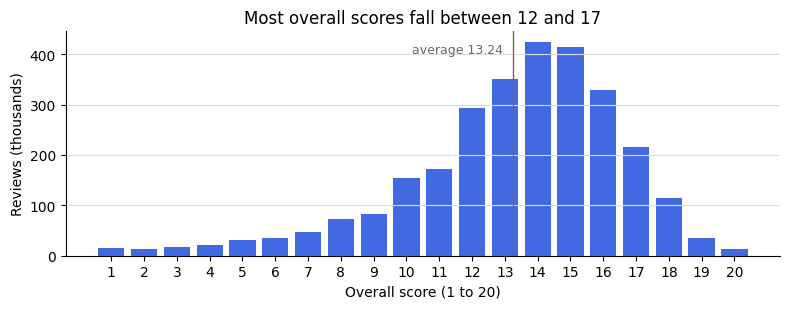

In [ ]:
overall_counts = df["overall"].value_counts().sort_index()
overall_mean = df["overall"].mean()
overall_variance = ((df["overall"] - overall_mean) ** 2).mean()
print(f"mean {overall_mean:.2f} | variance {overall_variance:.2f} | skew {df['overall'].skew():.2f}")
print(f"share of scores from 12 to 17: {df['overall'].between(12, 17).mean() * 100:.1f}%")

figure, axis = plt.subplots(figsize=(8, 3.2))
axis.bar(overall_counts.index, overall_counts.values / 1000, color=main_color, width=0.8)
axis.axvline(overall_mean, color=text_color, linewidth=1)
axis.text(overall_mean - 0.3, overall_counts.max() / 1000 * 0.95, f"average {overall_mean:.2f}", ha="right", color=text_color, fontsize=9)
axis.set_xticks(range(1, 21))
axis.set_xlabel("Overall score (1 to 20)")
axis.set_ylabel("Reviews (thousands)")
axis.set_title("Most overall scores fall between 12 and 17")
axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The average overall score is 13.24, and 71% of scores fall between 12 and 17. The distribution leans left with a skew of -1.03. Low scores trail off in a long tail while top scores are rare. Always predicting the average gives an MSE equal to the variance of 11.07.

## Patterns

users: % of users {'1': 32.8, '2-5': 27.5, '6-10': 9.5, '11-50': 14.0, '51-100': 3.9, '101-500': 7.7, '501-1000': 2.1, 'over 1000': 2.5}
users: % of reviews {'1': 0.3, '2-5': 0.8, '6-10': 0.8, '11-50': 3.2, '51-100': 2.9, '101-500': 18.0, '501-1000': 15.0, 'over 1000': 59.0}
beers: % of beers {'1': 22.5, '2-5': 34.0, '6-10': 14.5, '11-50': 20.9, '51-100': 3.7, '101-500': 3.7, '501-1000': 0.6, 'over 1000': 0.3}
beers: % of reviews {'1': 0.9, '2-5': 4.1, '6-10': 4.3, '11-50': 17.9, '51-100': 10.1, '101-500': 30.3, '501-1000': 15.8, 'over 1000': 16.7}


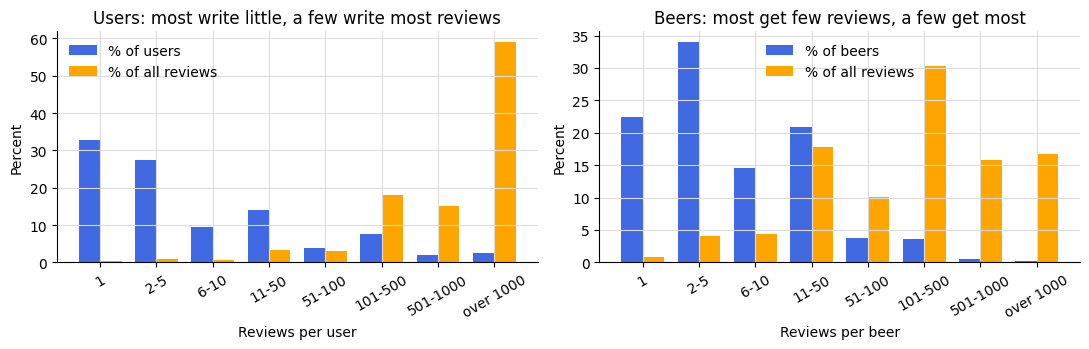

In [ ]:
bucket_edges = [0, 1, 5, 10, 50, 100, 500, 1000, 100000]
bucket_labels = ["1", "2-5", "6-10", "11-50", "51-100", "101-500", "501-1000", "over 1000"]
bar_positions = np.arange(len(bucket_labels))

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for axis, counts, group_label in [(axes[0], reviews_per_user, "users"), (axes[1], reviews_per_beer, "beers")]:
    bucket = pd.cut(counts, bins=bucket_edges, labels=bucket_labels)
    share_of_group = bucket.value_counts(normalize=True).sort_index() * 100
    share_of_reviews = counts.groupby(bucket, observed=False).sum() / len(df) * 100
    print(f"{group_label}: % of {group_label}", share_of_group.round(1).to_dict())
    print(f"{group_label}: % of reviews", share_of_reviews.round(1).to_dict())
    axis.bar(bar_positions - 0.19, share_of_group.values, width=0.38, color=main_color, label="% of " + group_label)
    axis.bar(bar_positions + 0.19, share_of_reviews.values, width=0.38, color=second_color, label="% of all reviews")
    axis.set_xticks(bar_positions, bucket_labels, rotation=30)
    axis.set_xlabel("Reviews per " + group_label[:-1])
    axis.set_ylabel("Percent")
    axis.legend(frameon=False)
axes[0].set_title("Users: most write little, a few write most reviews")
axes[1].set_title("Beers: most get few reviews, a few get most")
plt.tight_layout()
plt.show()

A third of users wrote just one review, while the 4.6% who wrote over 500 produced 74% of all reviews. Similarly, 4.6% of beers received 63% of the reviews. Heavy users and popular beers dominate the MSE.

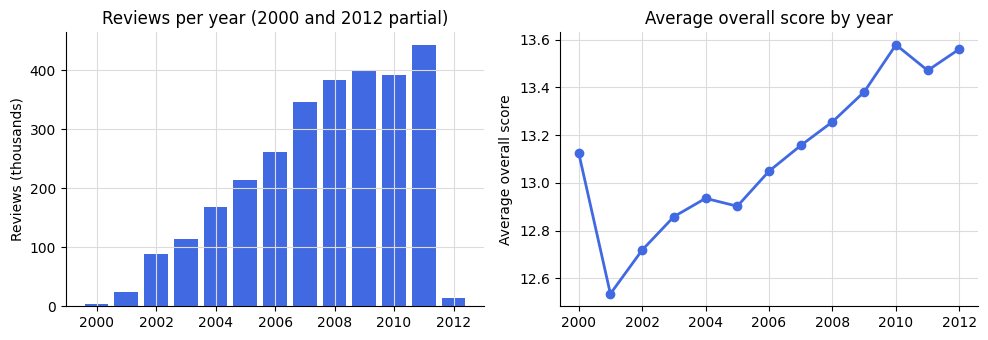

In [ ]:
review_year = df["date"].dt.year
reviews_per_year = df.groupby(review_year)["overall"].count()
average_by_year = df.groupby(review_year)["overall"].mean()

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(reviews_per_year.index, reviews_per_year.values / 1000, color=main_color)
axes[0].set_title("Reviews per year (2000 and 2012 partial)")
axes[0].set_ylabel("Reviews (thousands)")
axes[1].plot(average_by_year.index, average_by_year.values, color=main_color, linewidth=2, marker="o")
axes[1].set_title("Average overall score by year")
axes[1].set_ylabel("Average overall score")
for axis in axes:
    axis.set_xticks(range(2000, 2013, 2))
plt.tight_layout()
plt.show()

Reviews grow to about 400,000 a year by 2009–2011, and the average score rises from about 12.5 (2001) to about 13.5 (2010–2012). A year term in the model can capture this.

## Beer style and strength

Most reviewed styles: India Pale Ale (IPA), Pale Lager, Belgian Strong Ale, Imperial Stout, Imperial/Double IPA
Lowest: {'Low Alcohol': 6.33, 'Malt Liquor': 6.81, 'Pale Lager': 7.49}
Highest: {'Abt/Quadrupel': 15.68, 'Ice Cider/Perry': 15.81, 'Imperial Stout': 15.87}


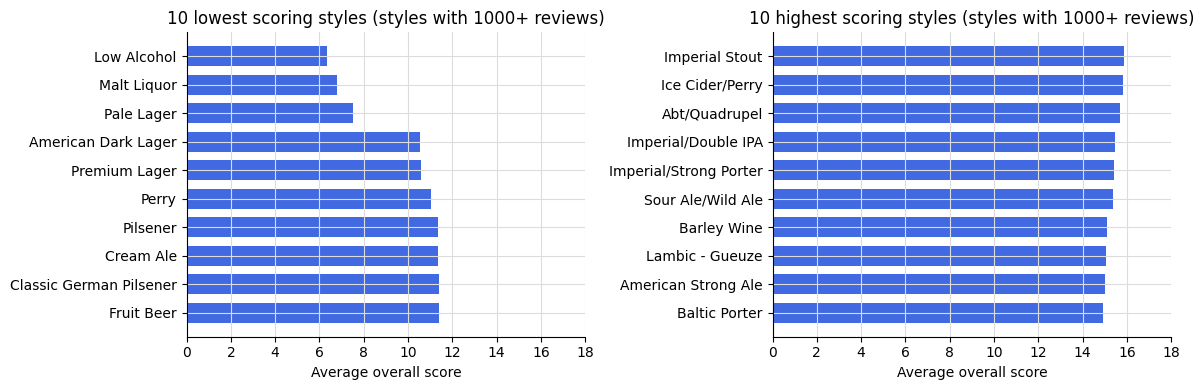

In [ ]:
style_summary = df.groupby("beer_style")["overall"].agg(["mean", "count"])
common_styles = style_summary[style_summary["count"] >= 1000].sort_values("mean")
print("Most reviewed styles:", ", ".join(style_summary.sort_values("count", ascending=False).index[:5]))
print("Lowest:", common_styles["mean"].head(3).round(2).to_dict())
print("Highest:", common_styles["mean"].tail(3).round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, styles_to_plot, panel_title in [(axes[0], common_styles.head(10).iloc[::-1], "10 lowest scoring styles"),
                                          (axes[1], common_styles.tail(10), "10 highest scoring styles")]:
    axis.barh(styles_to_plot.index, styles_to_plot["mean"], color=main_color, height=0.7)
    axis.set_xlim(0, 18)
    axis.set_xlabel("Average overall score")
    axis.set_title(panel_title + " (styles with 1000+ reviews)")
plt.tight_layout()
plt.show()

Average overall by ABV range: {'0-3': 7.33, '3-4': 11.28, '4-5': 11.48, '5-6': 12.94, '6-7': 14.09, '7-8': 14.38, '8-9': 14.7, '9-10': 15.24, '10-12': 15.47, '12-15': 15.48, '15+': 15.08}


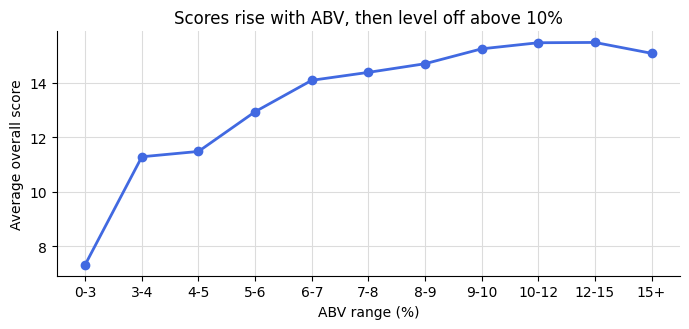

In [ ]:
abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 60]
abv_labels = ["0-3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15+"]
average_by_abv = df.groupby(pd.cut(df["abv"], bins=abv_edges, labels=abv_labels), observed=False)["overall"].mean()
print("Average overall by ABV range:", average_by_abv.round(2).to_dict())

figure, axis = plt.subplots(figsize=(7, 3.4))
axis.plot(abv_labels, average_by_abv.values, color=main_color, linewidth=2, marker="o")
axis.set_xlabel("ABV range (%)")
axis.set_ylabel("Average overall score")
axis.set_title("Scores rise with ABV, then level off above 10%")
plt.tight_layout()
plt.show()

*   style: averages run from about 6 (low alcohol beer, malt liquor) to almost 16 (imperial stout, quadrupel, double IPA), and IPA is the most reviewed style.
*   ABV: the average score climbs from 7.3 below 3% to about 15.5 at 10-15%, then dips slightly. Because this is a curve, not a straight line, the model uses ABV ranges instead of the raw number. Style and ABV overlap, because strong styles are high in alcohol.

In [ ]:
sample = df.loc[df["text"].notnull(), ["text", "overall"]].sample(n=50000, random_state=42)
sample = sample[(sample["overall"] <= 8) | (sample["overall"] >= 17)]
words = sample["text"].str.lower().str.translate(str.maketrans("", "", string.punctuation)).str.split()
is_low = (sample["overall"] <= 8).to_numpy()
low_counts = words[is_low].explode().value_counts()
high_counts = words[~is_low].explode().value_counts()
counts = pd.DataFrame({"low": low_counts, "high": high_counts}).fillna(0)
counts = counts[counts["low"] + counts["high"] >= 50]
low_rate = counts["low"] / low_counts.sum() * 10000
high_rate = counts["high"] / high_counts.sum() * 10000
low_ratio = ((low_rate + 1) / (high_rate + 1)).sort_values(ascending=False).head(12)
high_ratio = ((high_rate + 1) / (low_rate + 1)).sort_values(ascending=False).head(12)
pd.DataFrame({"low-score word": low_ratio.index, "x more common in low reviews": low_ratio.round(1).values,
              "high-score word": high_ratio.index, "x more common in high reviews": high_ratio.round(1).values},
             index=range(1, 13))

,low-score word,x more common in low reviews,high-score word,x more common in high reviews
1,corn,18.6,bourbon,12.6
2,watery,15.8,rich,10.2
3,boring,8.6,complex,8.6
4,bland,8.5,excellent,8.2
5,water,7.8,oak,7.7
6,weak,7.6,delicious,7.3
7,cheap,7.6,chocolate,7.3
8,bad,7.4,coffee,6.7
9,skunky,7.2,balanced,6.3
10,lager,6.9,pine,6.2


Low scores bring words like corn, watery, bland, skunky and cheap; high scores bring bourbon, rich, complex, oak and delicious. The text clearly carries information about the score, so we test text based models later too.

users with 10+ reviews: 9,233, st. dev. of their averages 1.98, middle half between 12.4 and 14.8
beers with 10+ reviews: 34,477, st. dev. of their averages 2.30


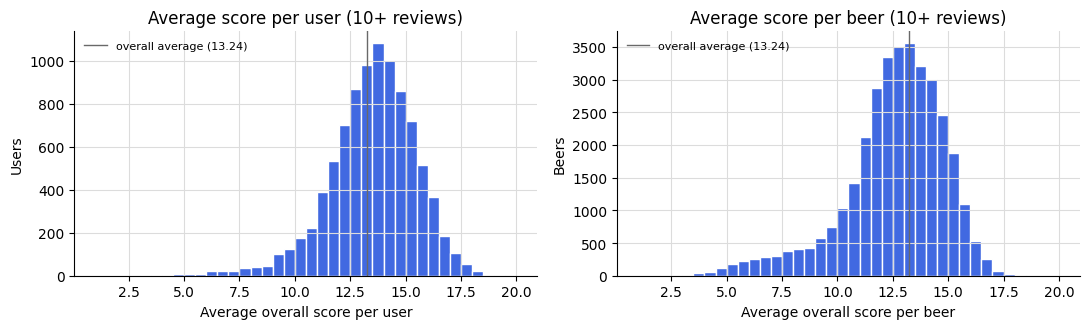

In [ ]:
active_users = df.groupby("user")["overall"].agg(["mean", "count"]).query("count >= 10")["mean"]
reviewed_beers = df.groupby("beer_id")["overall"].agg(["mean", "count"]).query("count >= 10")["mean"]
print(f"users with 10+ reviews: {len(active_users):,}, st. dev. of their averages {active_users.std():.2f}, "
      f"middle half between {active_users.quantile(0.25):.1f} and {active_users.quantile(0.75):.1f}")
print(f"beers with 10+ reviews: {len(reviewed_beers):,}, st. dev. of their averages {reviewed_beers.std():.2f}")

figure, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for axis, averages, label in [(axes[0], active_users, "user"), (axes[1], reviewed_beers, "beer")]:
    axis.hist(averages, bins=np.arange(1, 20.5, 0.5), color=main_color, edgecolor="white")
    axis.axvline(overall_mean, color=text_color, linewidth=1, label=f"overall average ({overall_mean:.2f})")
    axis.set_xlabel(f"Average overall score per {label}")
    axis.set_ylabel(label.capitalize() + "s")
    axis.set_title(f"Average score per {label} (10+ reviews)")
    axis.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Users differ in how generous they are (the middle half average between 12.4 and 14.8), and beers differ even more (standard deviation 2.30 vs. 1.98 for users). Bias model captures both with one offset per user and one per beer.

Score minus own average, by review number: {'1': 0.59, '2-5': 0.19, '6-10': 0.01, '11-25': -0.14, '26-50': -0.2, '51-100': -0.15, '101-250': -0.05, '251-500': -0.02, '501-1000': 0.01, '1001-2500': 0.05, '2500+': 0.15}


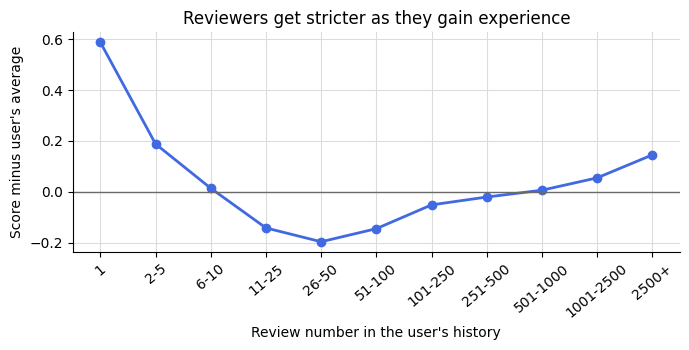

In [ ]:
user_history = df[["user", "date"]].sort_values(["user", "date"], kind="stable")
df["review_number"] = user_history.groupby("user").cumcount() + 1

experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, 100000]
experience_labels = ["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-250", "251-500", "501-1000", "1001-2500", "2500+"]
experience_range = pd.cut(df["review_number"], bins=experience_edges, labels=experience_labels)
difference_from_own_average = df["overall"] - df.groupby("user")["overall"].transform("mean")
heavy_user_rows = df.groupby("user")["overall"].transform("count") >= 50
within_user_by_experience = difference_from_own_average[heavy_user_rows].groupby(experience_range[heavy_user_rows], observed=False).mean()
print("Score minus own average, by review number:", within_user_by_experience.round(2).to_dict())

figure, axis = plt.subplots(figsize=(7, 3.6))
axis.plot(experience_labels, within_user_by_experience.values, color=main_color, linewidth=2, marker="o")
axis.axhline(0, color=text_color, linewidth=1)
axis.set_xticks(range(len(experience_labels)), experience_labels, rotation=40)
axis.set_xlabel("Review number in the user's history")
axis.set_ylabel("Score minus user's average")
axis.set_title("Reviewers get stricter as they gain experience")
plt.tight_layout()
plt.show()

Compared with their own average, users' first reviews are about 0.6 points more generous, and reviews 11-100 are slightly harsher. People become stricter as they gain experience, so the model includes an experience term.